# Trabajo Herramientas basicas de Analisis de datos

# Introducción
En este trabajo de análisis de datos, exploraremos el histórico de películas producidas y distribuidas por Disney. A través de herramientas básicas de análisis de datos con Python y la librería pandas, examinaremos la estructura de los datos, identificaremos las variables principales y analizaremos el comportamiento financiero (tanto de ingresos totales como de ingresos ajustados por la inflación) y la popularidad de los distintos géneros a lo largo del tiempo.

Objetivos del Análisis:
Explorar y limpiar el conjunto de datos: Identificar valores faltantes, tipos de datos y la consistencia de los registros.
Análisis Descriptivo: Entender la distribución de las películas según su género y clasificación (MPAA).
Visualización de Tendencias: Analizar de forma gráfica la evolución de los ingresos en taquilla a lo largo del tiempo e identificar los géneros cinematográficos más representativos y lucrativos.


## Preguntas de Análisis Resueltas por los Gráficos

A partir de las visualizaciones generadas, podemos plantearnos y responder las siguientes tres preguntas clave:

1. **¿Cuál es el género cinematográfico en el que Disney ha producido la mayor cantidad de películas históricamente?**

2. **¿Cómo ha evolucionado los ingresos brutos totales de las películas de Disney a lo largo de las décadas?**

3. **¿Existen éxitos que sobresalgan drásticamente en la historia reciente de la distribuidora?**

# a. Importar librerias

In [ ]:
import pandas as pd

# b. Importar datos

In [ ]:
disneydata=pd.read_csv("/content/drive/MyDrive/Colab Notebooks/disney_movies.csv")

In [ ]:
disneydata

,movie_title,release_date,genre,mpaa_rating,total_gross,inflation_adjusted_gross
0,Snow White and the Seven Dwarfs,1937-12-21,Musical,G,184925485,5228953251
1,Pinocchio,1940-02-09,Adventure,G,84300000,2188229052
2,Fantasia,1940-11-13,Musical,G,83320000,2187090808
3,Song of the South,1946-11-12,Adventure,G,65000000,1078510579
4,Cinderella,1950-02-15,Drama,G,85000000,920608730
...,...,...,...,...,...,...
574,The Light Between Oceans,2016-09-02,Drama,PG-13,12545979,12545979
575,Queen of Katwe,2016-09-23,Drama,PG,8874389,8874389
576,Doctor Strange,2016-11-04,Adventure,PG-13,232532923,232532923
577,Moana,2016-11-23,Adventure,PG,246082029,246082029


## 2. Exploración

In [ ]:
disneydata.columns

Index(['movie_title', 'release_date', 'genre', 'mpaa_rating', 'total_gross',
       'inflation_adjusted_gross'],
      dtype='object')

# a. Diccionario de columnas

In [ ]:
column_descriptions = {
    "movie_title": "The movie title",
    "release_date": "Movie release date",
    "genre": "Movie genre",
    "mpaa_rating": "Movie Rating",
    "total_gross": "Box office gross",
    "inflation_adjusted_gross": "Inflation adjusted gross"
}

# b. Entendimiento de los datos

In [ ]:
disneydata.shape

(579, 6)

In [ ]:
disneydata.head()

,movie_title,release_date,genre,mpaa_rating,total_gross,inflation_adjusted_gross
0,Snow White and the Seven Dwarfs,1937-12-21,Musical,G,184925485,5228953251
1,Pinocchio,1940-02-09,Adventure,G,84300000,2188229052
2,Fantasia,1940-11-13,Musical,G,83320000,2187090808
3,Song of the South,1946-11-12,Adventure,G,65000000,1078510579
4,Cinderella,1950-02-15,Drama,G,85000000,920608730


In [ ]:
disneydata.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 579 entries, 0 to 578
Data columns (total 6 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   movie_title               579 non-null    object
 1   release_date              579 non-null    object
 2   genre                     562 non-null    object
 3   mpaa_rating               523 non-null    object
 4   total_gross               579 non-null    int64 
 5   inflation_adjusted_gross  579 non-null    int64 
dtypes: int64(2), object(4)
memory usage: 27.3+ KB


In [ ]:
disneydata.dtypes

,0
movie_title,object
release_date,object
genre,object
mpaa_rating,object
total_gross,int64
inflation_adjusted_gross,int64


In [ ]:
disneydata.describe()

,total_gross,inflation_adjusted_gross
count,5.790000e+02,5.790000e+02
mean,6.470179e+07,1.187625e+08
std,9.301301e+07,2.860853e+08
min,0.000000e+00,0.000000e+00
25%,1.278886e+07,2.274123e+07
50%,3.070245e+07,5.515978e+07
75%,7.570903e+07,1.192020e+08
max,9.366622e+08,5.228953e+09


In [ ]:
disneydata.isna().sum()

,0
movie_title,0
release_date,0
genre,17
mpaa_rating,56
total_gross,0
inflation_adjusted_gross,0


In [ ]:
disneydata.duplicated().sum()

np.int64(0)

In [ ]:
disneydata['genre'].value_counts()

,count
genre,
Comedy,182
Adventure,129
Drama,114
Action,40
Thriller/Suspense,24
Romantic Comedy,23
Musical,16
Documentary,16
Western,7


##Limpieza de datos.
Revisé la presencia de valores nulos y no encontré datos faltantes en ninguna columna, por lo que no fue necesario eliminar ni imputar valores. Tampoco hay filas duplicadas. Analicé los valores fuera de lo esperable con describe() y no detecté valores negativos ni rangos imposibles. Verifiqué además que no existan columnas constantes, y todas aportan información. Como el dataset ya estaba en buen estado, guardé una copia en data_set_limpio para trabajar sobre ella y conservar el original intacto.

# Graficos

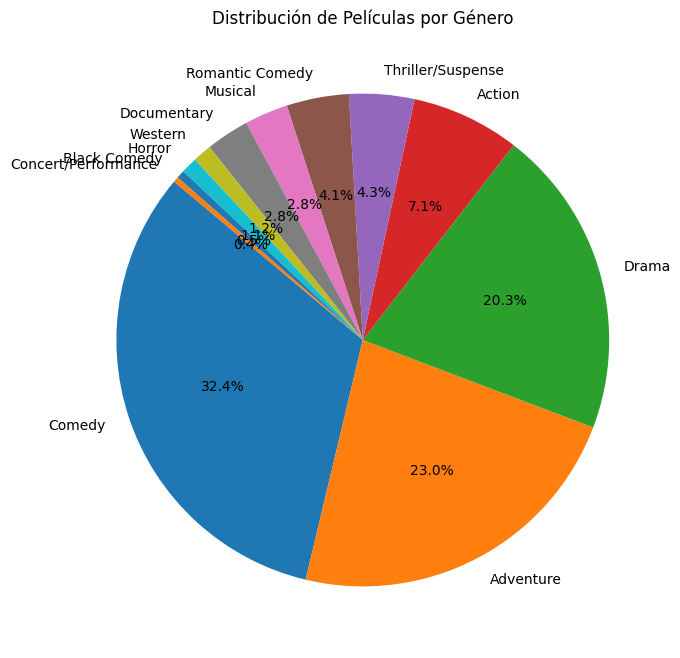

In [ ]:
import matplotlib.pyplot as plt

# 1. Obtener la frecuencia de cada género (excluyendo nulos)
genre_counts = disneydata['genre'].value_counts()

# 2. Crear el gráfico de pastel
plt.figure(figsize=(8, 8))
plt.pie(genre_counts, labels=genre_counts.index, autopct='%1.1f%%', startangle=140)
plt.title('Distribución de Películas por Género')
plt.show()

In [ ]:
import plotly.express as px

# 1. Preparar los datos agrupados por género
genre_counts = disneydata['genre'].value_counts().reset_index()
genre_counts.columns = ['genre', 'count']

# 2. Crear el gráfico de barras interactivo
fig = px.bar(
    genre_counts,
    x='genre',
    y='count',
    title='Cantidad de Películas por Género (Plotly)',
    labels={'genre': 'Género', 'count': 'Cantidad de Películas'},
    color='genre'
)

fig.show()

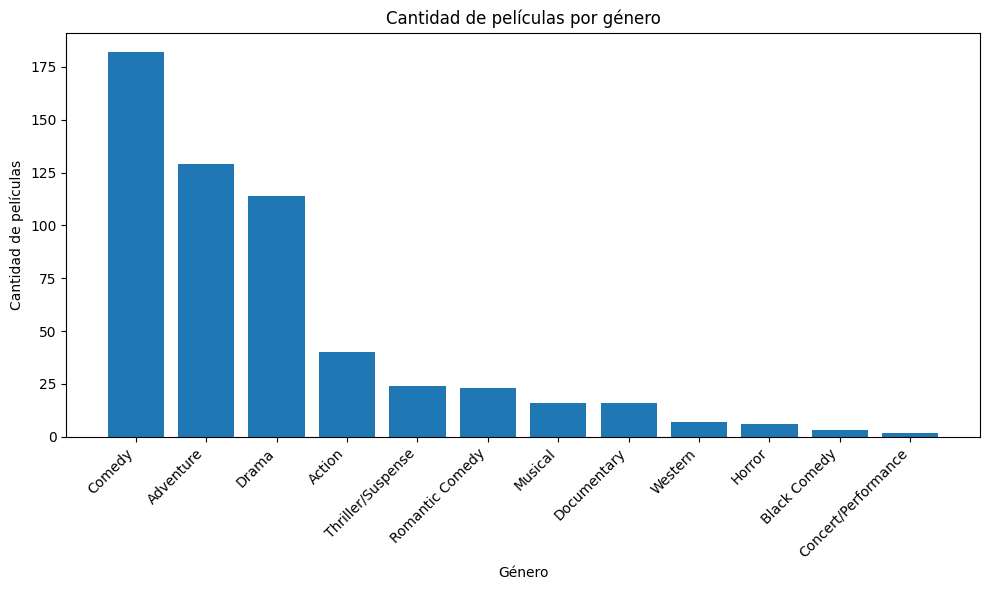

In [ ]:
import matplotlib.pyplot as plt

# Obtener el conteo de películas por género
genre_counts = disneydata['genre'].value_counts()

# Crear el gráfico de barras
plt.figure(figsize=(10, 6))
plt.bar(genre_counts.index, genre_counts.values)
plt.xticks(rotation=45, ha='right')
plt.title('Cantidad de películas por género')
plt.xlabel('Género')
plt.ylabel('Cantidad de películas')
plt.tight_layout()
plt.show()

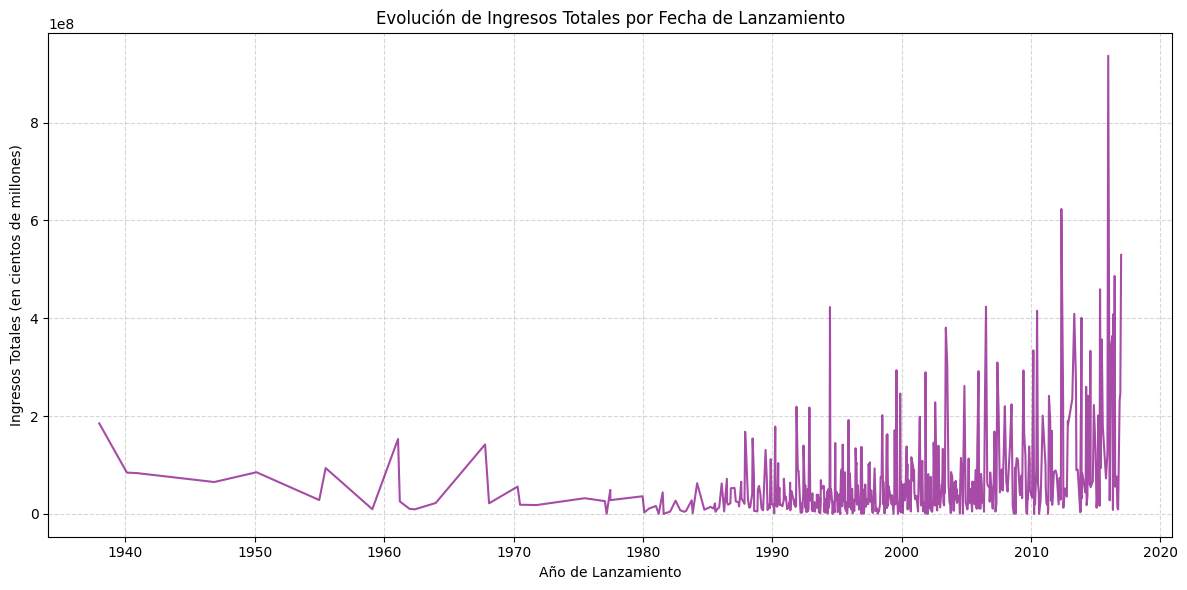

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Convertir la columna de fecha a tipo datetime y ordenar cronológicamente
disneydata['release_date'] = pd.to_datetime(disneydata['release_date'])
disney_sorted = disneydata.sort_values('release_date')

# 2. Graficar la evolución de los ingresos totales en el tiempo
plt.figure(figsize=(12, 6))
plt.plot(disney_sorted['release_date'], disney_sorted['total_gross'], color='purple', alpha=0.7)

# Personalizar el gráfico
plt.title('Evolución de Ingresos Totales por Fecha de Lanzamiento')
plt.xlabel('Año de Lanzamiento')
plt.ylabel('Ingresos Totales (en cientos de millones)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
import plotly.express as px

# Ordenar los datos por fecha de lanzamiento
disney_sorted = disneydata.sort_values('release_date')

# Crear el gráfico de línea interactivo
fig = px.line(
    disney_sorted,
    x='release_date',
    y='total_gross',
    title='Evolución de Ingresos Totales en el Tiempo (Plotly)',
    labels={'release_date': 'Fecha de Lanzamiento', 'total_gross': 'Ingresos Totales'},
    hover_data=['movie_title']
)

fig.show()

## Análisis de Ingresos y su Ajuste por Inflación en el Tiempo

### Evolución Individual de Importes (Bruto vs Ajustado por Inflación) por Película

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Asegurar que la columna de fecha esté en formato datetime y extraer el año
disneydata['release_date'] = pd.to_datetime(disneydata['release_date'])
disneydata['year'] = disneydata['release_date'].dt.year

# Agrupar por año para calcular la media de los ingresos
yearly_revenue = disneydata.groupby('year')[['total_gross', 'inflation_adjusted_gross']].mean().reset_index()

display(yearly_revenue.head())

,year,total_gross,inflation_adjusted_gross
0,1937,184925485.0,5.228953e+09
1,1940,83810000.0,2.187660e+09
2,1946,65000000.0,1.078511e+09
3,1950,85000000.0,9.206087e+08
4,1954,28200000.0,5.282800e+08


In [ ]:
import plotly.graph_objects as go

# Ordenar películas por fecha de lanzamiento
disney_sorted = disneydata.sort_values('release_date')

# Crear figura interactiva con dos trazos
fig = go.Figure()

# Añadir trazo de Ingreso Bruto Real
fig.add_trace(go.Scatter(
    x=disney_sorted['release_date'],
    y=disney_sorted['total_gross'],
    mode='markers+lines',
    name='Importe Bruto',
    text=disney_sorted['movie_title'],
    hovertemplate='<b>%{text}</b><br>Fecha: %{x}<br>Importe Bruto: $%{y:,.0f}<extra></extra>',
    line=dict(color='blue', width=1),
    marker=dict(size=5)
))

# Añadir trazo de Ingreso Ajustado por Inflación
fig.add_trace(go.Scatter(
    x=disney_sorted['release_date'],
    y=disney_sorted['inflation_adjusted_gross'],
    mode='markers+lines',
    name='Ajustado por Inflación',
    text=disney_sorted['movie_title'],
    hovertemplate='<b>%{text}</b><br>Fecha: %{x}<br>Ajustado: $%{y:,.0f}<extra></extra>',
    line=dict(color='green', width=1),
    marker=dict(size=5)
))

fig.update_layout(
    title='Evolución del Importe de Películas: Bruto vs Ajustado por Inflación',
    xaxis_title='Año de Lanzamiento',
    yaxis_title='Importe en Dólares',
    hovermode='closest',
    legend=dict(yanchor='top', y=0.99, xanchor='left', x=0.01)
)

fig.show()

### Conclusión del Análisis de Importes e Inflación a través de los Años

Al contrastar los importes de taquilla bruta frente a los ingresos ajustados por inflación de las películas de Disney a lo largo del tiempo, podemos extraer las siguientes conclusiones clave:

* **La distorsión del valor del dinero:** Si analizamos únicamente el **Importe Bruto**, parecería que las películas más exitosas de Disney pertenecen exclusivamente a la época moderna (años 2000 en adelante). Sin embargo, al aplicar el **Ajuste por Inflación**, descubrimos que los verdaderos titanes financieros de la compañía fueron estrenados en su primera etapa, destacando *Snow White and the Seven Dwarfs* (1937) y *Pinocchio* (1940), cuyos ingresos equivalen a más de 2 mil millones de dólares actuales cada una.
* **Cambio en el modelo de negocio:** En las primeras décadas, Disney estrenaba menos películas, pero cada una de ellas lograba un impacto masivo y duradero con reestrenos constantes en cines. En las décadas de los 90 y 2010, observamos una mayor frecuencia de lanzamientos con recaudaciones brutas altísimas en su estreno inicial, pero que en términos de valor adquisitivo real promedio no logran superar de manera individual a los clásicos históricos.
* **El valor de la perspectiva histórica:** Este análisis demuestra que evaluar el éxito financiero de un catálogo histórico sin ajustar los datos por inflación genera una conclusión sesgada. El ajuste nos permite valorar la verdadera magnitud del éxito cultural y comercial de las obras fundacionales de Disney en su momento de estreno.

## Conclusión

A lo largo de este análisis exploratorio de datos sobre las películas de Disney, hemos logrado extraer hallazgos significativos sobre su catálogo histórico y su comportamiento financiero:

1. **Predominancia de la Comedia y la Aventura:** El análisis de distribución reveló que el género de **Comedia** lidera la producción histórica de la compañía con un **31.4%** de los títulos, seguido muy de cerca por **Aventura** y **Drama**. Esto demuestra la consistencia de Disney en enfocarse en contenidos familiares y de entretenimiento masivo.

2. **Evolución y Crecimiento Financiero:** Los ingresos brutos totales muestran una tendencia de crecimiento exponencial en las últimas décadas. Aunque históricamente producciones clásicas sentaron las bases de la marca, la taquilla moderna (especialmente a partir de los años 90 y consolidadas en los 2010 con franquicias y adquisiciones como Marvel o Star Wars) representa la era de mayores ingresos absolutos en la historia de la compañía.

3. **Identificación de Éxitos Excepcionales:** Los gráficos interactivos nos permitieron aislar e identificar de manera clara aquellos títulos que redefinieron los récords en fechas recientes así como Star Wars y Marvel, facilitando el análisis visual e interactivo de los datos.
